# D1 · Purchasing patterns in the training period

How big is a typical basket? How often does a customer buy the same product again? Run this CPU notebook from top to bottom to answer those questions using paid merchandise baskets completed from **1 December 2010 through 30 September 2011**. The input tables come from the D1 cleaning notebook. The outputs are four CSVs, a JSON summary and three figures under `results/training_eda/`. [D1 cleaning](project2_colab.ipynb) · [Research plan v3.4, §2](../docs/CS5481_Project2_Research_Development_Plan_3.4.en.md) · [UCI Online Retail, Chen (2015), CC BY 4.0](https://doi.org/10.24432/C5BW33)

# D1 · 训练期的购物篮与购买模式

一张购物篮通常有几种商品？客户有多少次购买是复购？在 CPU 上从上往下运行，即可用 **2010 年 12 月 1 日至 2011 年 9 月 30 日**完成的付费商品购物篮回答这些问题。输入来自 D1 清洗，四份 CSV、一份 JSON 摘要和三张图写入 `results/training_eda/`。[D1 清洗](project2_colab.ipynb) · [研究计划 v3.4 第 2 节](../docs/CS5481_Project2_Research_Development_Plan_3.4.md) · [UCI Online Retail，Chen（2015），CC BY 4.0](https://doi.org/10.24432/C5BW33)

## Open the two cleaned tables

In Colab, authorize Drive access. The default project folder is `My Drive/CS5481_Project2_OnlineRetail`. The notebook first looks for both cleaned tables and their manifest. If the set is incomplete, it downloads the published D1 files at revision `083f2c8` to the runtime and saves the EDA results to your Drive project. Locally, open this notebook in a repository checkout with D1 outputs. Each input is checked against its SHA-256 digest.

## 读取清洗后的两张表

在 Colab 授权挂载 Drive。默认项目文件夹为 `我的云端硬盘/CS5481_Project2_OnlineRetail`。优先读取项目中的两张清洗表及其清单；如果这三份文件不齐，则将 GitHub 上 `083f2c8` 版本的 D1 文件下载到临时运行环境，分析结果仍保存到 Drive 项目文件夹。本地在含有 D1 产物的仓库内打开即可。每份输入都按清单核对 SHA-256。

In [1]:
from pathlib import Path
import hashlib
import json
from tempfile import TemporaryDirectory
from urllib.error import URLError
from urllib.request import urlretrieve
import pandas as pd
from IPython.display import Image, display

EVENT_PATH = "data/processed/basket_events.csv.gz"
LINE_PATH = "data/processed/purchase_lines.csv.gz"
MANIFEST_PATH = "results/data_manifest.json"


def load_training_inputs(project):
    """Verify both D1 exports against their manifest before reading the source rows."""
    manifest = json.loads((project / MANIFEST_PATH).read_text(encoding="utf-8"))
    input_hashes = {}
    for relative in (EVENT_PATH, LINE_PATH):
        with (project / relative).open("rb") as stream:
            digest = hashlib.file_digest(stream, "sha256").hexdigest()
        if digest != manifest["outputs"][relative]["sha256"]:
            raise ValueError(f"File differs from its D1 cleaning manifest: {relative}")
        input_hashes[relative] = digest
    identifiers = {"CustomerID": "string", "InvoiceNo": "string", "StockCode": "string"}
    events = pd.read_csv(project / EVENT_PATH, dtype=identifiers, keep_default_na=False,
                         parse_dates=["basket_time"])
    lines = pd.read_csv(project / LINE_PATH, dtype=identifiers, keep_default_na=False,
                        usecols=["ExcelRow", *identifiers, "InvoiceDate", "Quantity", "UnitPrice"],
                        parse_dates=["InvoiceDate"])
    return events, lines, input_hashes

In [2]:
try:
    from google.colab import drive
except ImportError:
    drive = None

if drive is None:
    project = Path("..") if Path.cwd().name == "notebooks" else Path(".")
else:
    drive.mount("/content/drive")
    project = Path("/content/drive/MyDrive/CS5481_Project2_OnlineRetail")
    if not project.is_dir():
        selected = input(f"Drive project folder / Drive 项目文件夹 [Enter = {project}]：").strip()
        if selected:
            project = Path(selected)
            if not project.is_absolute() or not project.is_dir():
                raise ValueError("Choose an existing Drive project folder / 请选择已有项目文件夹")

def notebook_inputs(project, allow_download):
    paths = (MANIFEST_PATH, EVENT_PATH, LINE_PATH)
    if all((project / path).is_file() for path in paths):
        print("D1 data / D1 数据源：", project)
        return load_training_inputs(project)
    if not allow_download:
        raise FileNotFoundError("Run the D1 cleaning notebook or python -m scripts.prepare_data first. / 请先完成 D1 清洗。")
    revision = "083f2c8514e3bb9824f4f9855176b76e5afb534e"
    base = f"https://raw.githubusercontent.com/NobunagaK/online-retail-top10-recommendation/{revision}"
    print("D1 data from GitHub / 从 GitHub 读取固定版本：", revision)
    with TemporaryDirectory() as work:
        cached = Path(work)
        for relative in paths:
            dest = cached / relative
            dest.parent.mkdir(parents=True, exist_ok=True)
            try:
                urlretrieve(f"{base}/{relative}", dest)
            except URLError as exc:
                raise RuntimeError("Download failed. Run D1 cleaning in this Drive folder and retry. / 下载失败，请在此 Drive 文件夹运行 D1 清洗后重试。") from exc
        return load_training_inputs(cached)

all_events, all_lines, input_hashes = notebook_inputs(project, allow_download=drive is not None)
output_dir = project / "results/training_eda"
print("Results / 结果目录：", output_dir)

D1 data / D1 数据源： ..


Results / 结果目录： ../results/training_eda


## Select complete baskets and recover their source lines

Use the half-open window `[2010-12-01, 2011-10-01)` on `basket_time`, the last retained line time for a customer invoice. Select source lines using both customer and invoice identifiers. This matters for unit prices because a basket-item can combine differently priced lines. Check the first and last included completion times, then reconcile line, unit and amount totals. The entire training period is appropriate for these descriptive statistics. Each future D2 monthly example can use only history preceding its own cutoff.

## 按完成时间选整篮，再找回对应明细

先用 `basket_time` 截取左闭右开的区间 `[2010-12-01, 2011-10-01)`。它是同一客户这张发票最后一条有效明细的时间。再按客户编号和发票号一同找回明细，因为一个购物篮商品事件可能合并了不同单价的行。下面核对首末时间、明细数、件数和金额。整段训练期可用于描述统计。后续 D2 每个月的训练样本仍只能使用该月截止点之前的历史。

In [3]:
INVOICE_KEYS = ["CustomerID", "InvoiceNo"]
TRAIN_START = pd.Timestamp("2010-12-01")
TRAIN_END = pd.Timestamp("2011-10-01")


def select_training_data(
    events: pd.DataFrame, purchase_lines: pd.DataFrame, start=TRAIN_START, end=TRAIN_END,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Select whole baskets in [start, end) and their retained purchase lines.

    The event table supplies one completion time per (CustomerID, InvoiceNo).
    A basket completed at the cutoff is excluded even if some lines are earlier.
    Read CSV identifiers as strings to preserve their original spelling and zeros.
    """
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    if start >= end:
        raise ValueError("The training start must be earlier than the end.")
    times = pd.to_datetime(events["basket_time"])
    selected = times.ge(start) & times.lt(end)
    train_events = events.loc[selected].copy()
    train_events["basket_time"] = times.loc[selected]
    train_events = train_events.sort_values(
        ["basket_time", *INVOICE_KEYS, "StockCode"], ignore_index=True,
    )
    baskets = train_events[[*INVOICE_KEYS, "basket_time"]].drop_duplicates()
    train_lines = purchase_lines.merge(baskets, on=INVOICE_KEYS, how="inner", validate="many_to_one")
    train_lines["InvoiceDate"] = pd.to_datetime(train_lines["InvoiceDate"])
    if train_lines["InvoiceDate"].gt(train_lines["basket_time"]).any():
        raise ValueError("A retained invoice line is dated after its basket's completion.")
    if len(train_lines) != train_events["source_lines"].sum():
        raise ValueError("Training basket source-line counts differ from the matched purchase lines.")
    return train_events, train_lines.sort_values("ExcelRow", ignore_index=True)
events, lines = select_training_data(all_events, all_lines)
assert events["basket_time"].ge(TRAIN_START).all() and events["basket_time"].lt(TRAIN_END).all()
assert events["source_lines"].sum() == len(lines)
assert events["quantity"].sum() == lines["Quantity"].sum()
import math
assert math.isclose(events["amount_gbp"].sum(), (lines["Quantity"] * lines["UnitPrice"]).sum(), abs_tol=1e-6, rel_tol=0)
display(pd.Series({
    "first_completed": events["basket_time"].min(), "last_completed": events["basket_time"].max(),
    "source_lines": len(lines), "basket_item_events": len(events),
    "baskets": len(events[INVOICE_KEYS].drop_duplicates()),
    "customers": events["CustomerID"].nunique(), "items": events["StockCode"].nunique(),
}).to_frame("training_window"))

,training_window
first_completed,2010-12-01 08:26:00
last_completed,2011-09-30 15:52:00
source_lines,262597
basket_item_events,260199
baskets,13081
customers,3613
items,3501


## How does purchasing activity change by month?

Assign each basket to its month of completion. Count distinct customers within each month, which means a returning customer can contribute to several monthly totals. Sum events, units, and recorded GBP across months. September had the most baskets (1,739) and item events (39,154). February had the fewest events (19,423), while January had the fewest baskets (983). These are observed monthly totals in this retailer’s ten-month window.

## 每个月的交易量怎样变化？

将每个购物篮归入完成月份。每月统计不同客户，同一客户可能在不同月份重复出现。事件、件数与英镑金额则可跨月加总。9 月购物篮与商品事件均最多（1,739 篮、39,154 次事件）；事件最少的是 2 月（19,423 次），篮子最少的是 1 月（983 篮）。这些结论针对这家零售商实际观测到的十个月。

In [4]:
def monthly_activity(train_events: pd.DataFrame, start=TRAIN_START, end=TRAIN_END) -> pd.DataFrame:
    """Summarize each calendar month, including empty months within [start, end).

    Each basket and all its item events belong to its completion month. Customer
    counts are monthly distinct customers. Amounts preserve sub-penny GBP.
    """
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    if start >= end:
        raise ValueError("The training start must be earlier than the end.")
    times = pd.to_datetime(train_events["basket_time"])
    selected = times.ge(start) & times.lt(end)
    events = train_events.loc[selected].assign(month=times.loc[selected].dt.to_period("M"))
    monthly = events.groupby("month").agg(
        active_customers=("CustomerID", "nunique"),
        basket_item_events=("StockCode", "size"),
        source_lines=("source_lines", "sum"),
        units=("quantity", "sum"),
        amount_gbp=("amount_gbp", "sum"),
    )
    baskets = events[["month", *INVOICE_KEYS]].drop_duplicates()
    monthly.insert(1, "baskets", baskets.groupby("month").size())
    months = pd.period_range(start, end - pd.Timedelta(nanoseconds=1), freq="M", name="month")
    monthly = monthly.reindex(months, fill_value=0)
    monthly.index = monthly.index.astype(str)
    return monthly.reset_index()
monthly = monthly_activity(events)
assert monthly["basket_item_events"].sum() == len(events)
assert monthly["source_lines"].sum() == len(lines)
display(monthly)

,month,active_customers,baskets,basket_item_events,source_lines,units,amount_gbp
0,2010-12,884,1394,25209,25569,310623,565199.560
1,2011-01,739,983,20680,20896,348178,562682.910
2,2011-02,757,992,19423,19630,264785,442293.590
3,2011-03,973,1312,26497,26750,347243,583143.850
4,2011-04,853,1139,22191,22346,291117,454440.881
5,2011-05,1054,1544,27765,27959,372587,659227.490
6,2011-06,990,1390,26613,26811,362716,653114.920
7,2011-07,946,1321,26228,26463,367042,591431.291
8,2011-08,933,1267,26439,26673,397089,635371.880
9,2011-09,1259,1739,39154,39500,542815,938625.131


## What does a typical purchase look like?

Use one observation per retained source line for price and quantity, one per completed invoice for basket size, and one per customer for the two history measures. Customer history length counts one event per distinct SKU per basket, including repeat purchases across baskets. Percentiles use linear interpolation. The median line has a unit price of £1.95 and quantity of 6. The median basket contains 15 distinct SKUs. The median customer history contains 34 events across the period, and the median number of baskets per customer is 2. The largest values remain visible in the tables and figures.

## 典型的一次购买是什么样？

统计单价与购买数量时，每条保留的原始明细计一次；统计购物篮大小时，每张客户发票计一次；统计历史长度时，每位客户计一次。相同商品在一个篮子里算一次事件，跨篮再购买会增加历史长度。分位数用线性插值计算。单价中位数为 £1.95，明细数量中位数为 6 件；每篮商品种数中位数为 15，每位客户的历史事件数中位数为 34，购物篮数中位数为 2。表和图都保留极端值。

In [5]:
def distribution_tables(
    train_events: pd.DataFrame, train_lines: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Return exact-value frequencies and summaries of five training distributions.

    Price and quantity are observed once per source line, with no quantity
    weighting. Basket size counts distinct SKUs per completed customer invoice.
    History length counts basket-item events per customer across the full training
    window, including repeat purchases on later invoices. Basket frequency counts
    distinct completed invoices per customer in that same window. Quantiles use
    linear interpolation on the individual observations.
    """
    baskets = train_events.groupby(INVOICE_KEYS)["StockCode"].nunique()
    distributions = {
        "line_unit_price_gbp": (train_lines["UnitPrice"], "source line", "GBP per unit"),
        "line_quantity": (train_lines["Quantity"], "source line", "units"),
        "basket_distinct_skus": (baskets, "basket", "distinct SKUs"),
        "customer_history_events": (
            train_events.groupby("CustomerID").size(), "customer", "basket-item events",
        ),
        "customer_baskets": (
            baskets.groupby(level="CustomerID").size(), "customer", "baskets",
        ),
    }
    frequencies, summaries = [], []
    quantiles = {"p25": .25, "median": .5, "p75": .75, "p90": .90, "p95": .95, "p99": .99}
    for measure, (observations, observation_unit, value_unit) in distributions.items():
        counts = observations.value_counts().sort_index().rename_axis("value")
        frequencies.append(counts.rename("frequency").reset_index().assign(measure=measure))
        percentiles = observations.quantile(list(quantiles.values()))
        summaries.append({
            "measure": measure,
            "observation_unit": observation_unit,
            "value_unit": value_unit,
            "count": len(observations),
            "min": observations.min(),
            **{name: percentiles.loc[q] for name, q in quantiles.items()},
            "max": observations.max(),
            "mean": observations.mean(),
        })
    frequency_table = pd.concat(frequencies, ignore_index=True)[["measure", "value", "frequency"]]
    return frequency_table, pd.DataFrame(summaries)
frequency, distributions = distribution_tables(events, lines)
assert frequency.groupby("measure")["frequency"].sum().to_dict() == distributions.set_index("measure")["count"].to_dict()
display(distributions)
display(frequency.loc[frequency["measure"].eq("line_unit_price_gbp")].head())

,measure,observation_unit,value_unit,count,min,p25,median,p75,p90,p95,p99,max,mean
0,line_unit_price_gbp,source line,GBP per unit,262597,0.001,1.25,1.95,3.75,6.75,8.5,12.75,649.5,2.943482
1,line_quantity,source line,units,262597,1.000,2.00,6.00,12.00,24.00,48.0,144.00,74215.0,13.725195
2,basket_distinct_skus,basket,distinct SKUs,13081,1.000,6.00,15.00,26.00,43.00,57.0,93.20,418.0,19.891369
3,customer_history_events,customer,basket-item events,3613,1.000,15.00,34.00,79.00,161.80,248.2,501.52,4811.0,72.017437
4,customer_baskets,customer,baskets,3613,1.000,1.00,2.00,4.00,8.00,11.0,24.88,138.0,3.620537


,measure,value,frequency
0,line_unit_price_gbp,0.001,3
1,line_unit_price_gbp,0.040,39
2,line_unit_price_gbp,0.060,58
3,line_unit_price_gbp,0.070,6
4,line_unit_price_gbp,0.080,35


## Which products reach the most customers?

Rank each exact product code by its number of distinct purchasing customers. Break a tie by the original StockCode in ascending order, then take the first 10% of SKUs rounded up. In this window the leading 351 of 3,501 SKUs account for 121,547 of 260,199 events (46.71%). SKU 22423 reaches 750 customers, while SKU 85123A has more events but reaches 728 customers. Reach measures how widely an item was purchased. The head’s event share measures how concentrated purchases are.

## 哪些商品覆盖的购买客户最多？

每种商品按不同购买客户数降序排列，同值按原始 StockCode 升序排列，取商品数的前 10% 并向上取整。训练期共 3,501 种商品，其中前 351 种占 260,199 次事件中的 121,547 次（46.71%）。商品 22423 覆盖 750 位客户；商品 85123A 的购买事件更多，但覆盖 728 位客户。购买客户数描述覆盖面，热门组的事件占比描述购买量的集中程度。

In [6]:
def _share(numerator: int, denominator: int) -> float | None:
    return numerator / denominator if denominator else None

item_key = ["CustomerID", "InvoiceNo", "StockCode"]
if events[[*item_key, "basket_time"]].isna().any().any():
    raise ValueError("Each basket-item event needs a customer, invoice, SKU and completion time.")
if events.duplicated(item_key).any():
    raise ValueError("Expected one event per customer, invoice and SKU.")

customers = int(events["CustomerID"].nunique())
popularity = (
    events.groupby("StockCode", as_index=False, sort=False, observed=True)
    .agg(purchasing_customers=("CustomerID", "nunique"), basket_item_events=("InvoiceNo", "size"))
    .sort_values(["purchasing_customers", "StockCode"], ascending=[False, True], ignore_index=True)
)
items = len(popularity)
# Integer ceiling gives exactly the leading 10% (rounded up), even with ties.
head_items = (items + 9) // 10
popularity.insert(0, "rank", range(1, items + 1))
popularity.insert(3, "customer_reach_share", popularity["purchasing_customers"] / customers)
popularity["is_head"] = popularity["rank"].le(head_items)
head = popularity.loc[popularity["is_head"]]
head_events = int(head["basket_item_events"].sum())
head_customers = int(events.loc[events["StockCode"].isin(head["StockCode"]), "CustomerID"].nunique())
display(popularity.head(10))
print("Top items / 热门商品数：", head_items)

,rank,StockCode,purchasing_customers,customer_reach_share,basket_item_events,is_head
0,1,22423,750,0.207584,1339,True
1,2,85123A,728,0.201495,1549,True
2,3,47566,646,0.178799,1201,True
3,4,21212,545,0.150844,807,True
4,5,22720,531,0.146969,869,True
5,6,84879,528,0.146139,992,True
6,7,85099B,518,0.143371,1186,True
7,8,22960,493,0.136452,702,True
8,9,22457,484,0.133961,733,True
9,10,23298,482,0.133407,791,True


Top items / 热门商品数： 351


## When does an event count as a repeat purchase?

For a given customer and SKU, compare each event with the earliest basket completion time in the training window. A later timestamp establishes a repeat. At identical first timestamps, the data establish no order. Customer 12540 bought SKU 85123A in July and again in September. Customer 12971 has two first entries for SKU 21448 at the same minute. Inspect both examples below. Purchases before the workbook begins are unknown.

## 什么时候算作一次复购？

对同一客户和同一商品，将每次事件与训练期首次购买的购物篮完成时间比较。严格更晚才算复购。如果两张发票的首次购买时间相同，就无法据此确定先后顺序。客户 12540 在 7 月和 9 月各买过一次 85123A；客户 12971 的两张发票则在同一分钟首次出现 21448。下方列出原始发票号供核对。工作簿开始以前的购买无法观察。

In [7]:
pair_key = ["CustomerID", "StockCode"]
pairs = events.groupby(pair_key, sort=False, observed=True)
observed_pairs = pairs.ngroups
possible_pairs = customers * items
# Two invoices at the same first completion time do not provide earlier
# history for one another. The unique event key makes any later match a
# different invoice for this customer and SKU.
repeat = events["basket_time"].gt(pairs["basket_time"].transform("min"))
repeat_events = int(repeat.sum())
repeat_pairs = len(events.loc[repeat, pair_key].drop_duplicates())
event_count = len(events)

summary = {
    "customers": customers,
    "items": items,
    "basket_item_events": event_count,
    "observed_customer_item_pairs": observed_pairs,
    "possible_customer_item_pairs": possible_pairs,
    "interaction_sparsity": 1 - observed_pairs / possible_pairs if possible_pairs else None,
    "repeat_purchase_events": repeat_events,
    "repeat_event_share": _share(repeat_events, event_count),
    "repeated_customer_item_pairs": repeat_pairs,
    "repeated_pair_share": _share(repeat_pairs, observed_pairs),
    "head_items": head_items,
    "head_purchase_events": head_events,
    "head_event_share": _share(head_events, event_count),
    "head_purchasing_customers": head_customers,
    "head_customer_reach_share": _share(head_customers, customers),
}
preferences = summary
display(pd.Series({
    "Repeat events / 复购事件": f"{repeat_events:,}",
    "All purchase events / 全部购买事件": f"{event_count:,}",
    "Repeat event share / 事件复购率": f"{preferences['repeat_event_share']:.2%}",
    "Repeated pairs / 发生复购的客户商品组合": f"{repeat_pairs:,}",
    "Observed pairs / 有购买记录的组合": f"{observed_pairs:,}",
    "Repeated pair share / 已购组合中发生复购的比例": f"{preferences['repeated_pair_share']:.2%}",
    "Possible pairs / 可能组合": f"{possible_pairs:,}",
    "Interaction sparsity / 稀疏度": f"{preferences['interaction_sparsity']:.2%}",
}).to_frame("training_value"))
trace = events.loc[
    (events["CustomerID"].eq("12540") & events["StockCode"].eq("85123A")) |
    (events["CustomerID"].eq("12971") & events["StockCode"].eq("21448")),
    ["CustomerID", "StockCode", "InvoiceNo", "basket_time", "quantity"],
].copy()
trace["strictly_later_repeat"] = repeat.loc[trace.index]
display(trace)

,training_value
Repeat events / 复购事件,"71,824"
All purchase events / 全部购买事件,"260,199"
Repeat event share / 事件复购率,27.60%
Repeated pairs / 发生复购的客户商品组合,"38,669"
Observed pairs / 有购买记录的组合,"188,368"
Repeated pair share / 已购组合中发生复购的比例,20.53%
Possible pairs / 可能组合,"12,649,113"
Interaction sparsity / 稀疏度,98.51%


,CustomerID,StockCode,InvoiceNo,basket_time,quantity,strictly_later_repeat
88316,12971,21448,547944,2011-03-28 14:59:00,12,False
88319,12971,21448,547946,2011-03-28 14:59:00,12,False
110548,12971,21448,550967,2011-04-21 16:58:00,12,True
188601,12540,85123A,561093,2011-07-25 10:01:00,12,False
248256,12540,85123A,568001,2011-09-23 11:35:00,12,True


## How frequent are repeats, and how sparse are the observations?

71,824 of 260,199 basket-item events (27.60%) have an earlier purchase of the same SKU by the same customer. At the customer–SKU pair level, 38,669 of 188,368 observed pairs (20.53%) repeat. Simply subtracting the number of observed pairs from all events would count seven additional events tied at their first timestamp. For sparsity the denominator is 3,613 active customers × 3,501 observed SKUs = 12,649,113 possible pairs. Only 188,368 pairs were observed, giving **98.51% sparsity**. An unobserved pair means no qualifying purchase was recorded in this window. These measurements describe the training data and supply context for later repeat, long-tail and cold-start evaluation.

## 复购有多常见？数据有多稀疏？

260,199 次商品事件中，有 71,824 次能找到同一客户在严格更早时购买同一商品的记录，事件复购率为 27.60%。换成不同的客户–商品组合做分母，188,368 个已观察组合中有 38,669 个发生复购，占 20.53%。直接用总事件数减去不同组合数，会多算 7 个在首次购买时并列的事件。计算稀疏度时，分母是 3,613 位活跃客户 × 3,501 种已购商品，共 12,649,113 种可能组合。实际观察到 188,368 种，因此**稀疏度为 98.51%**。未观察组合只表示这段时间没有记录到该客户对该商品的有效购买。后续可用这些统计解释复购、长尾和冷启动分组的评价结果。

## Draw the distributions from the exported counts

The monthly figure uses the monthly table. The distribution curves use the exact-value frequency table, including the extremes. The popularity figure uses the same sorted SKU list as the reported head count. Axis labels identify what is counted and in which units.

## 从统计表绘制结果图

月度图使用月度统计表；分布图使用各个取值的精确频数，包括极端值；商品热度图沿用热门组统计时的排序结果。每个坐标轴均注明所统计的对象或单位。

In [8]:
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter, MaxNLocator
import pandas as pd


BLUE = "#245e85"
TEAL = "#137563"
INK = "#1f3544"


def _number(value, position=None):
    if abs(value) >= 1_000_000:
        return f"{value / 1_000_000:g}M"
    if abs(value) >= 1_000:
        return f"{value / 1_000:g}k"
    return f"{value:,.6f}".rstrip("0").rstrip(".")


def _heading(figure, title, subtitle):
    figure.text(0.075, 0.97, title, va="top", fontsize=17, fontweight="bold", color=INK)
    figure.text(0.075, 0.915, subtitle, va="top", fontsize=10, color=INK)


def _style(axis):
    axis.spines[["top", "right"]].set_visible(False)
    axis.spines[["bottom", "left"]].set_color("#899aa3")
    axis.tick_params(labelsize=9, labelcolor=INK, color="#899aa3")
    axis.grid(axis="y", which="major", color="#dbe1e4", linewidth=0.7)
    axis.set_axisbelow(True)


def _monthly(monthly, window):
    figure = Figure(figsize=(11, 7))
    axes = figure.subplots(2, 2, sharex=True).flat
    figure.subplots_adjust(left=0.08, right=0.985, top=0.80, bottom=0.13, hspace=0.35, wspace=0.21)
    _heading(figure, "Monthly purchasing activity", f"{window}  ·  Month of basket completion")
    panels = [
        ("baskets", "Customer invoices (baskets)"),
        ("basket_item_events", "Distinct items summed across baskets (events)"),
        ("units", "Quantity purchased (units)"),
        ("amount_gbp", "Recorded purchase amount (GBP)"),
    ]
    month_labels = pd.PeriodIndex(monthly["month"], freq="M").strftime("%b\n%Y")
    for axis, (column, title) in zip(axes, panels):
        _style(axis)
        axis.bar(range(len(monthly)), monthly[column], color=BLUE, width=0.70)
        axis.set_title(title, fontsize=11, loc="left", color=INK)
        axis.set_ylim(bottom=0)
        axis.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=column != "amount_gbp"))
        axis.yaxis.set_major_formatter(FuncFormatter(_number))
        axis.set_xticks(range(len(monthly)), month_labels)
    return figure

In [9]:
def _distributions(distributions, window):
    figure = Figure(figsize=(12, 7.4))
    grid = figure.add_gridspec(2, 6, left=0.075, right=0.975, top=0.785,
                               bottom=0.09, wspace=0.78, hspace=0.52)
    _heading(figure, "Distribution of purchase lines, baskets and customer histories",
             f"{window}  ·  Share at or above each observed value  ·  Both axes logarithmic  ·  Full range")
    panels = [
        ("line_unit_price_gbp", "Unit price per purchase line", "GBP per unit", "Purchase lines (%)", grid[0, :3]),
        ("line_quantity", "Quantity per purchase line", "Units", "Purchase lines (%)", grid[0, 3:]),
        ("basket_distinct_skus", "Size of a basket", "Distinct SKUs", "Baskets (%)", grid[1, :2]),
        ("customer_history_events", "Events per customer", "Basket-item events", "Customers (%)", grid[1, 2:4]),
        ("customer_baskets", "Baskets per customer", "Completed baskets", "Customers (%)", grid[1, 4:]),
    ]
    for measure, title, unit, population, slot in panels:
        axis = figure.add_subplot(slot)
        _style(axis)
        axis.set_title(title, fontsize=11, loc="left", color=INK)
        axis.set_xlabel(unit, fontsize=10)
        axis.set_ylabel(population, fontsize=10)
        rows = distributions.loc[distributions["measure"] == measure].sort_values("value")
        if rows.empty:
            axis.text(0.5, 0.5, "No observations", transform=axis.transAxes, ha="center")
            continue
        # For an observed x, sum exact frequencies from x through the maximum.
        share = rows["frequency"].iloc[::-1].cumsum().iloc[::-1] * 100 / rows["frequency"].sum()
        axis.step(rows["value"], share, where="pre", color=TEAL, linewidth=1.8)
        axis.scatter(rows["value"].iloc[[0, -1]], share.iloc[[0, -1]], s=16, color=TEAL, zorder=3)
        axis.set_xscale("log")
        axis.set_yscale("log")
        axis.minorticks_off()
        axis.yaxis.set_major_formatter(FuncFormatter(_number))
        axis.xaxis.set_major_formatter(FuncFormatter(_number))
    return figure

In [10]:
def _popularity(popularity, window):
    figure = Figure(figsize=(10.5, 6))
    axis = figure.subplots()
    figure.subplots_adjust(left=0.10, right=0.975, top=0.80, bottom=0.14)
    _heading(figure, "Item popularity by customer reach",
             f"{window}  ·  All {len(popularity):,} training SKUs  ·  Logarithmic customer count")
    _style(axis)
    axis.set_xlabel("Item rank by number of distinct purchasing customers")
    axis.set_ylabel("Distinct customers purchasing the item")
    if not popularity.empty:
        ordered = popularity.sort_values("rank")
        head = ordered.loc[ordered["is_head"], "rank"]
        if not head.empty:
            axis.axvspan(0.5, head.max() + 0.5, color=TEAL, alpha=0.13,
                         label=f"Top 10% of items (ranks 1–{head.max():,})")
            axis.legend(loc="upper right", frameon=False, fontsize=10)
        axis.plot(ordered["rank"], ordered["purchasing_customers"], color=BLUE, linewidth=2)
        axis.set_yscale("log")
        axis.set_xlim(0.5, ordered["rank"].max() + 0.5)
        axis.minorticks_off()
    axis.yaxis.set_major_formatter(FuncFormatter(_number))
    axis.xaxis.set_major_locator(MaxNLocator(nbins=8, integer=True))
    return figure


def build_training_figures(tables: dict[str, pd.DataFrame]) -> dict[str, Figure]:
    """Build displayable, unsaved figures. The caller chooses file format and DPI."""
    monthly = tables["monthly_activity"].sort_values("month")
    periods = pd.PeriodIndex(monthly["month"], freq="M")
    window = "Training window"
    if len(periods):
        window += f" · {periods.min().strftime('%b %Y')}–{periods.max().strftime('%b %Y')}"
    return {
        "monthly_volume": _monthly(monthly, window),
        "size_distributions": _distributions(tables["distributions"], window),
        "item_popularity": _popularity(tables["item_popularity"], window),
    }

## Export the tables, figures and summary

The JSON summary records the interval, input file hashes, numerators, denominators and metric definitions. CSVs contain the ten monthly rows, exact frequencies, distribution summary and ranked SKU table. Each PNG can be used in the report. The CLI reproduces these same outputs with `python -m scripts.analyze_training`.

## 保存表格、图片与统计摘要

JSON 摘要记录日期边界、输入文件校验值、各指标的分子分母和定义。四份 CSV 依次保存月度活动、精确取值频数、分布分位数和商品热度排名。三张 PNG 图可直接用于报告。本地命令 `python -m scripts.analyze_training` 可复现相同的结果。

In [11]:
def summarize_window(train_events, train_lines, preferences, input_hashes):
    return {
        "window": {"field": "basket_time", "start_inclusive": TRAIN_START.isoformat(),
                   "end_exclusive": TRAIN_END.isoformat()},
        "input_sha256": input_hashes,
        "source_lines": len(train_lines),
        "baskets": len(train_events[["CustomerID", "InvoiceNo"]].drop_duplicates()),
        "units": int(train_events["quantity"].sum()),
        "recorded_amount_gbp": float(format(train_events["amount_gbp"].sum(), ".15g")),
        **preferences,
        "definitions": {
            "repeat_event_share": "Basket-item events with an earlier completed basket for the same customer and SKU / all training basket-item events. Equal timestamps provide no earlier history.",
            "repeated_pair_share": "Observed customer-SKU pairs with a strictly later purchase / all observed training customer-SKU pairs.",
            "interaction_sparsity": "1 - observed distinct customer-SKU pairs / (active customers x observed SKUs).",
            "head_items": "Ceiling of 10% of observed SKUs, ranked by distinct customers descending, then exact StockCode ascending.",
            "head_event_share": "Events for head SKUs / all training events.",
            "head_customer_reach_share": "Distinct customers with any head SKU / distinct active training customers.",
        },
    }


def save_training_eda(output_dir, tables, summary, figures):
    """Stage the tables and figures together and replace the summary last."""
    output_dir.mkdir(parents=True, exist_ok=True)
    with TemporaryDirectory(dir=output_dir) as dirname:
        staged = Path(dirname)
        paths = []
        for name, table in tables.items():
            path = staged / f"{name}.csv"
            table.to_csv(path, index=False, float_format="%.15g")
            paths.append(path)
        for name, figure in figures.items():
            path = staged / f"{name}.png"
            figure.savefig(path, format="png", dpi=170, bbox_inches="tight", facecolor="white")
            paths.append(path)
        summary_path = staged / "summary.json"
        summary_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False, allow_nan=False) + "\n",
                                encoding="utf-8")
        for path in [*paths, summary_path]:
            path.replace(output_dir / path.name)
tables = {"monthly_activity": monthly, "distributions": frequency, "distribution_summary": distributions,
          "item_popularity": popularity}
summary = summarize_window(events, lines, preferences, input_hashes)
figures = build_training_figures(tables)
save_training_eda(output_dir, tables, summary, figures)
print("Saved under / 保存目录：", output_dir)

Saved under / 保存目录： ../results/training_eda


### Monthly activity

Read each panel on its own vertical scale. Distinct customer counts by month are included in the CSV.

### 月度活动

各面板的纵轴单位不同。逐月活跃客户数可在月度 CSV 中查看。

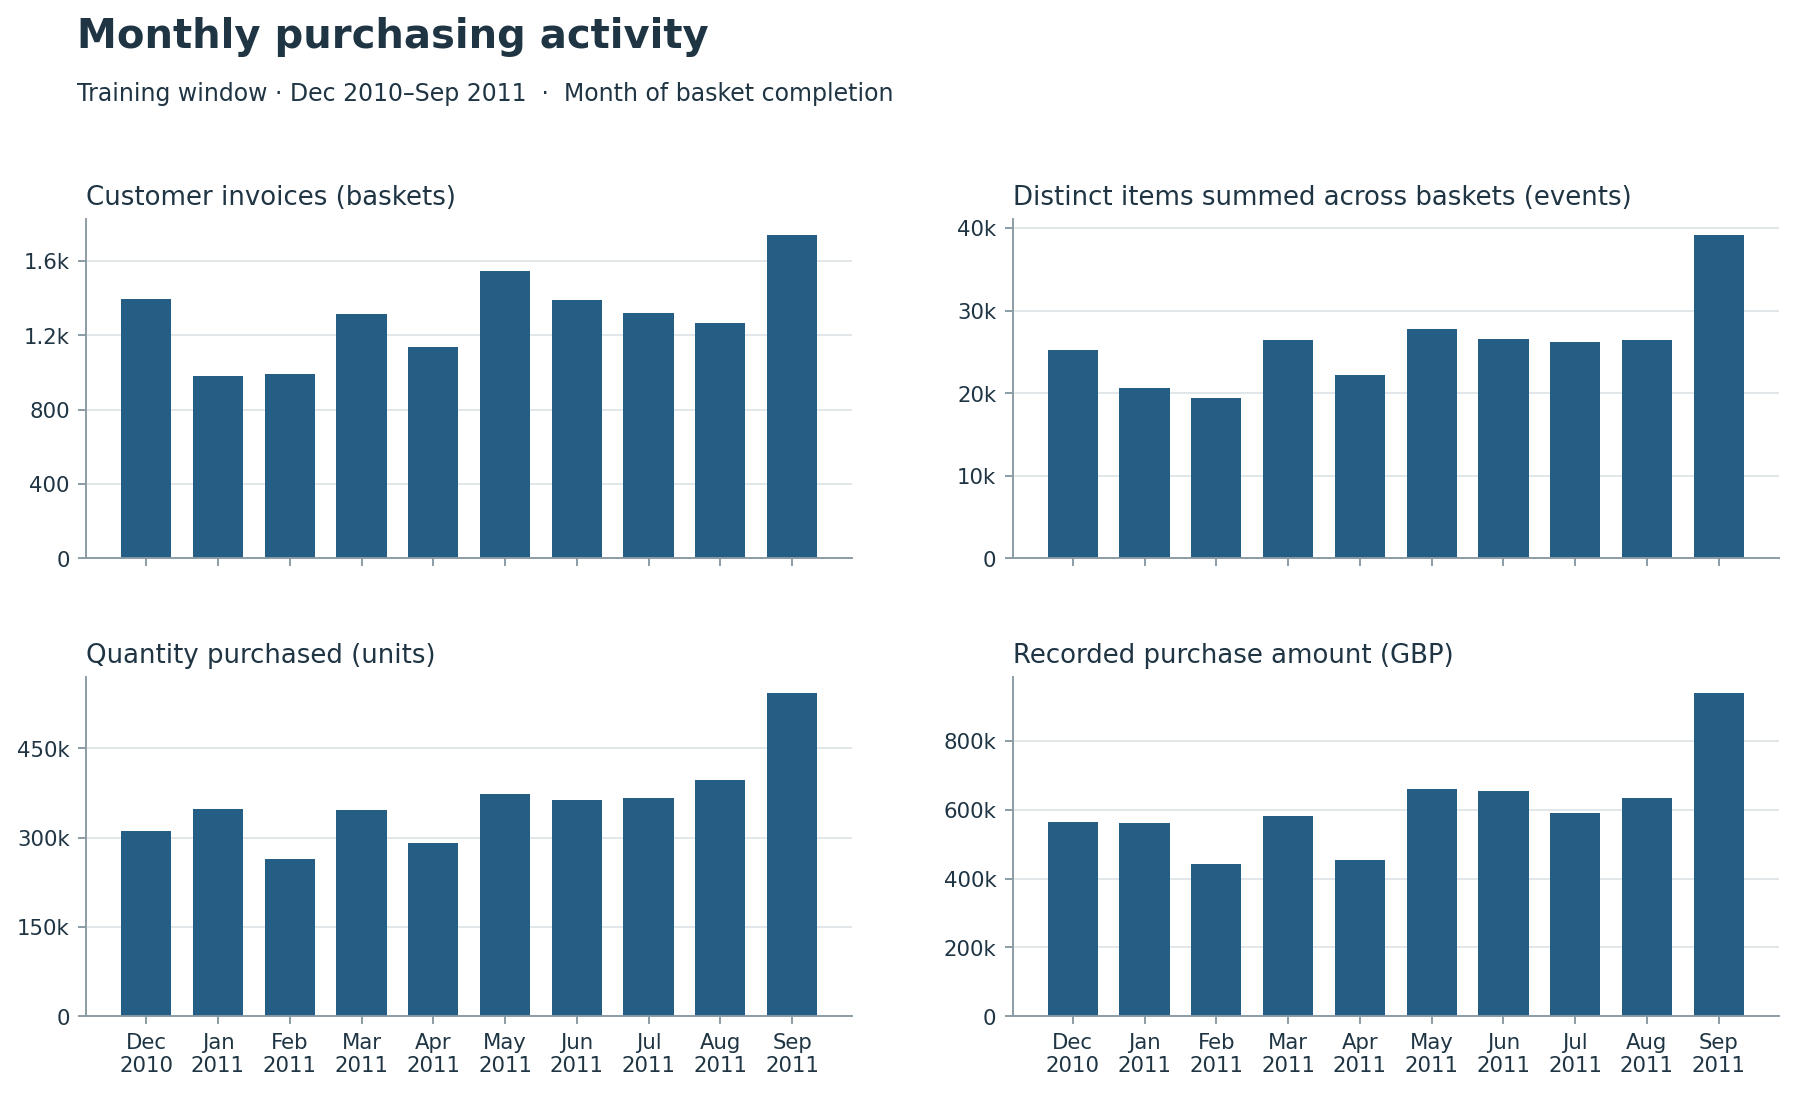

In [12]:
display(Image(filename=str(output_dir / "monthly_volume.png"), width=920))

### Size and price distributions

At a value x, the vertical axis shows the percentage of observations at or above x. Both axes are logarithmic. A small number of transactions sit far from the median, including a line of 74,215 units and a £0.001 cushion-pad price.

### 规模与价格分布

横轴取值 x 对应的纵轴是观测值大于等于 x 的百分比。两轴均为对数刻度。极少数明细远离中位数，例如一笔 74,215 件的购买，以及靠垫配套垫 £0.001 的单价。

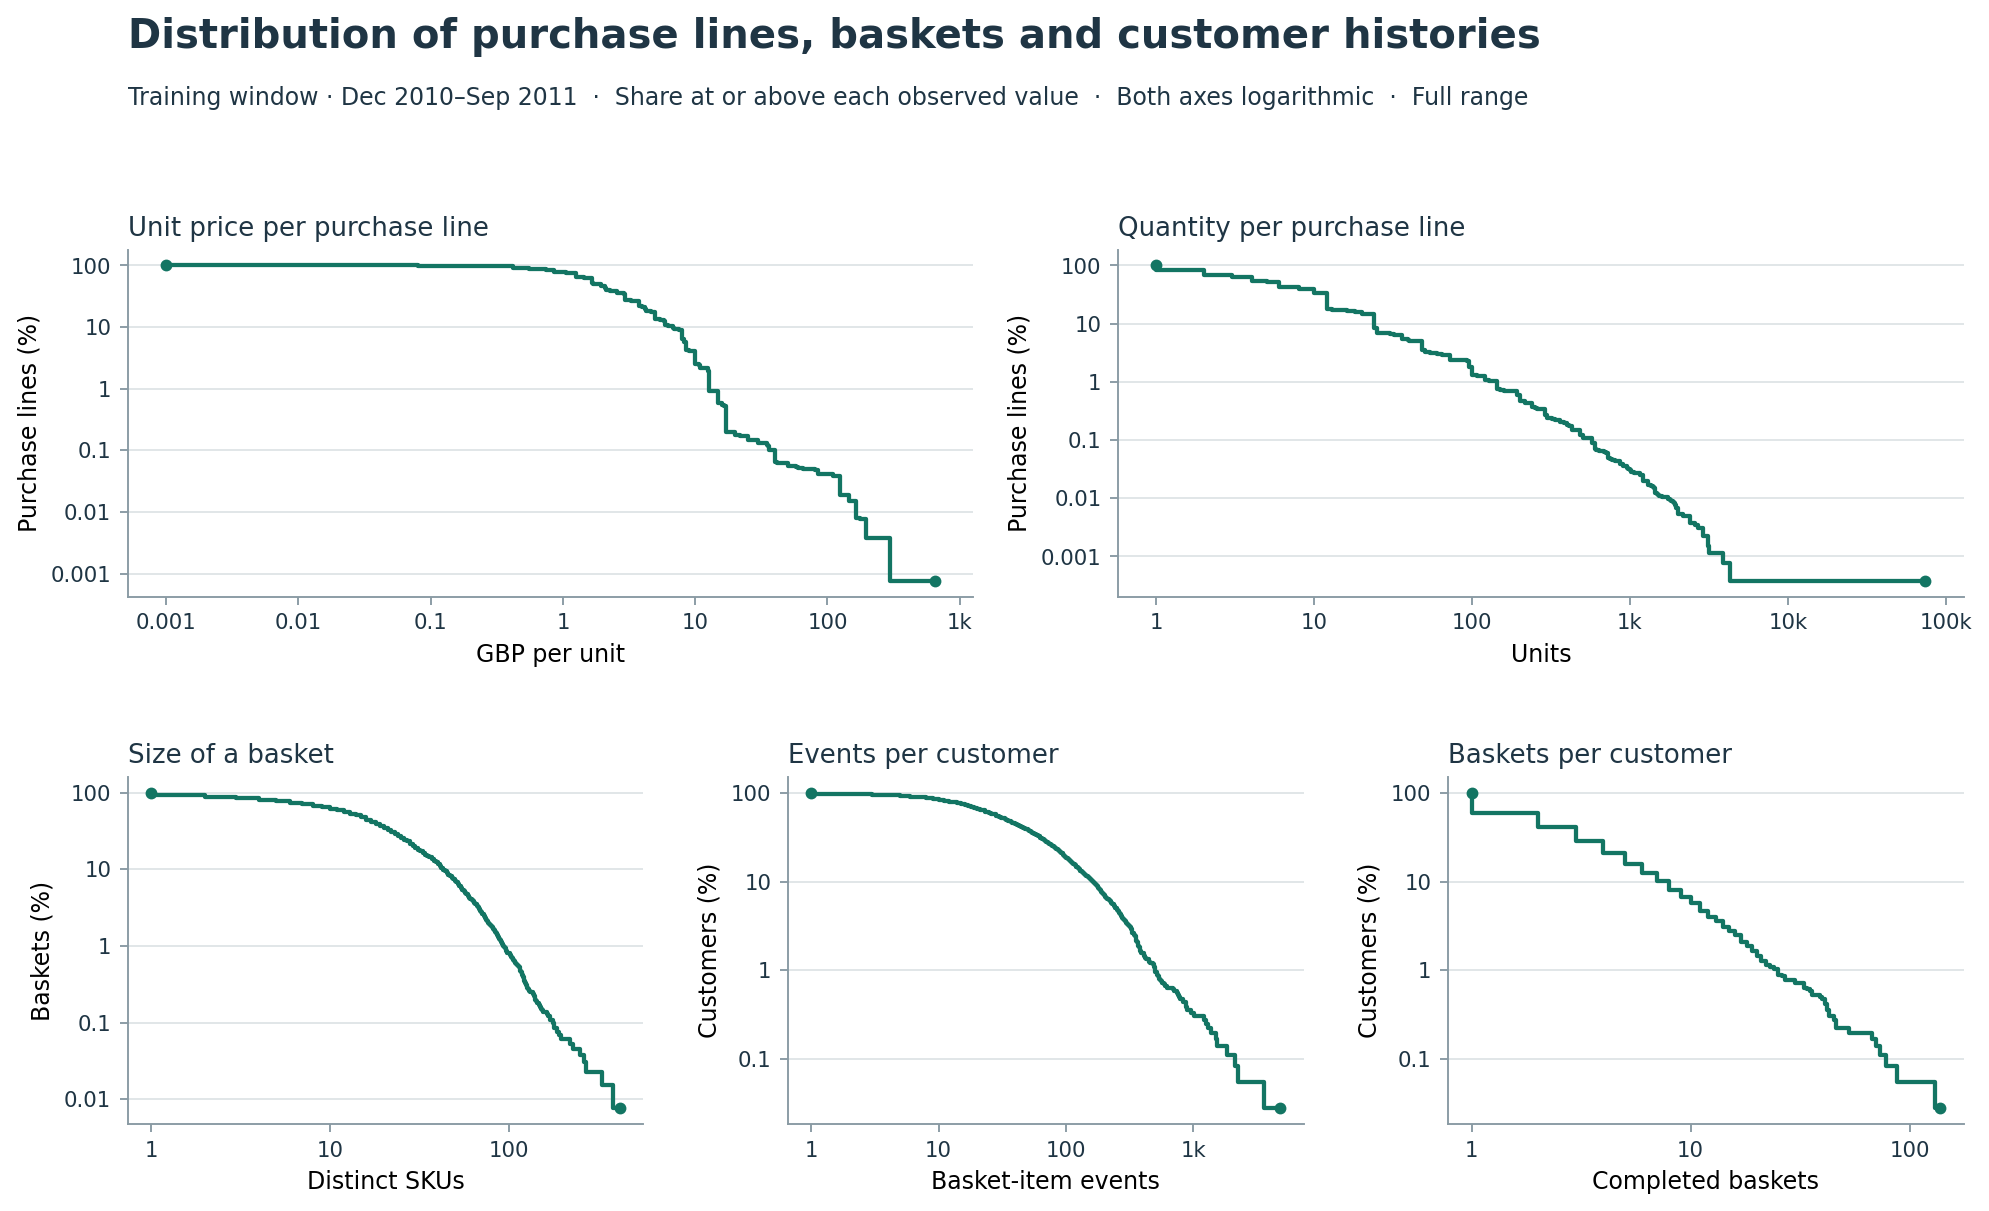

In [13]:
display(Image(filename=str(output_dir / "size_distributions.png"), width=920))

### Item popularity across the catalog

Each point represents one ranked SKU. The vertical axis is the number of distinct buyers on a log scale. Shading identifies ranks 1–351.

### 目录内商品的热度

每个排名位置对应一种商品，纵轴是对数刻度的不同购买客户数。阴影覆盖第 1 至 351 名。

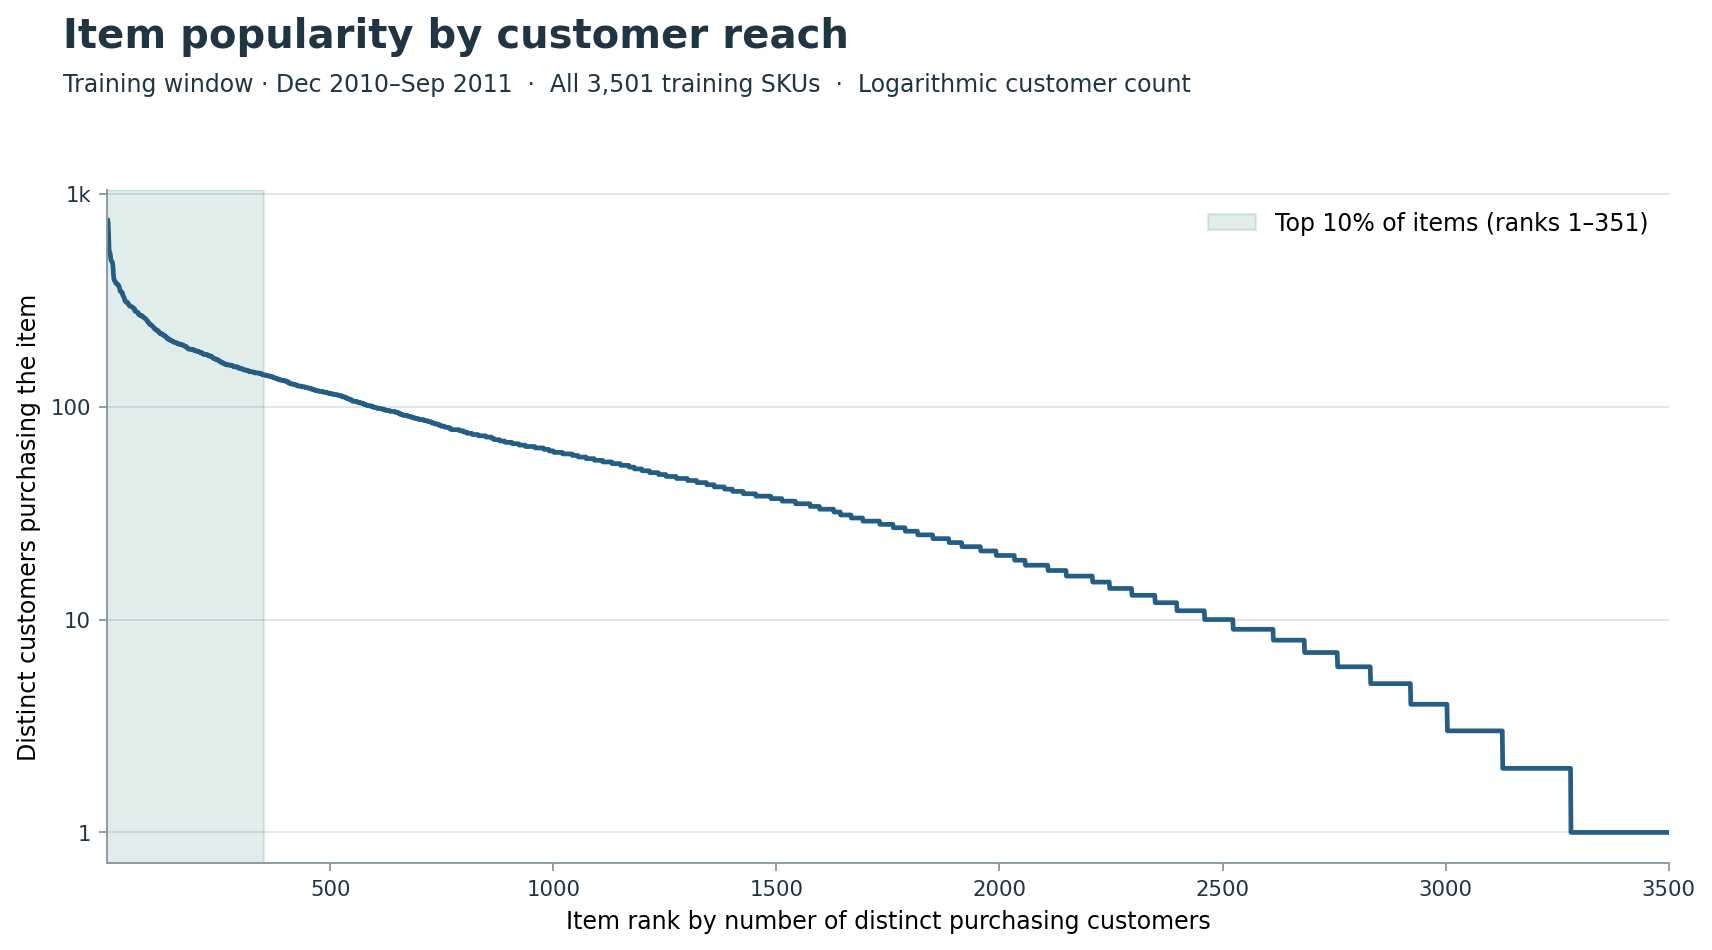

In [14]:
display(Image(filename=str(output_dir / "item_popularity.png"), width=920))